<a href="https://colab.research.google.com/github/pjacierda/busa3022-market-intelligence/blob/main/dashboard/dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/pjacierda/busa3022-market-intelligence/blob/main/dashboard/dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dashboard: ASX 200 market activity (Part 3)
BUSA3022 – Dashboard lead. **Question this answers:** *how has market activity trended over the past 90 days, and is there anything we should be watching?*

**Audience:** financially literate, non-technical bank managers.  **Run order:** Runtime → Run all. Column names live in cell 1, so a pipeline rename is a one-line fix.

**Components (brief, Part 3):** (1) price with a 20-day rolling-average overlay, (2) the macro overlay (Australian 10-year bond yield) showing correlation or divergence, (3) one Red/Amber/Green signal based on a justified threshold.

*AI disclosure: the code in this notebook was written with Claude (Anthropic) and then checked by the dashboard lead. Each metric has a hand-check cell that recomputes one value the long way. Plain-language metric definitions are in `docs/metric_definitions.md`, written before the code.*

In [1]:
# 1. Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import HTML, display

DATA_URL = "https://raw.githubusercontent.com/pjacierda/busa3022-market-intelligence/main/data/clean/market_daily.csv"
CLOSE = "asx200_close"          # column names live here: if the pipeline renames a column, change it once
YIELD = "bond10y_yield"
YIELD_FILLED = "bond10y_missing"  # True = yield carried forward because the RBA had not published it yet

In [2]:
# 2. Load the team's clean data (falls back to a manual upload if the repo link fails)
try:
    df = pd.read_csv(DATA_URL, parse_dates=["date"])
except Exception as e:
    print("Could not load from GitHub:", e)
    from google.colab import files
    uploaded = files.upload()      # pick the clean market_daily CSV from your computer
    df = pd.read_csv(next(iter(uploaded)), parse_dates=["date"])

df = df.sort_values("date").reset_index(drop=True)
print(df.shape)
df.tail()

Could not load from GitHub: HTTP Error 404: Not Found


Saving market_daily (2).csv to market_daily (2).csv
(378, 5)


,date,asx200_close,asx200_volume,bond10y_yield,bond10y_missing
373,2026-10-21,8831.299805,919200,5.277,False
374,2026-10-22,8793.200195,814800,5.277,True
375,2026-10-23,8795.200195,970700,5.277,True
376,2026-10-26,8809.900391,766800,5.277,True
377,2026-10-27,8850.099609,780700,5.277,True


In [3]:
# 3. Data checks (results feed the data-quality write-up)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Duplicate dates:", df["date"].duplicated().sum())
print("Missing closes:", df[CLOSE].isna().sum(), "| missing yields:", df[YIELD].isna().sum())
zero_vol = df.loc[df["asx200_volume"] == 0, "date"].dt.date.tolist()
print("Zero-volume days (volume is not used on the dashboard):", zero_vol)

# Yield: how much of it was really published by the RBA, and how stale is the newest value?
filled = df[YIELD_FILLED].astype(bool)
last_published = df.loc[~filled, "date"].max()
trailing_filled = int((df["date"] > last_published).sum())
print(f"Yield rows carried forward: {filled.sum()} of {len(df)} | last RBA value: {last_published.date()} | days since: {trailing_filled} trading days")

# The newest day is treated as provisional if its volume is 0 (figures not final yet)
latest = df.iloc[-1]
provisional = latest["asx200_volume"] == 0
print("Latest day:", latest["date"].date(), "| provisional?", provisional)

Date range: 2025-05-06 to 2026-10-27
Duplicate dates: 0
Missing closes: 0 | missing yields: 0
Zero-volume days (volume is not used on the dashboard): [datetime.date(2026, 6, 29)]
Yield rows carried forward: 6 of 378 | last RBA value: 2026-10-21 | days since: 4 trading days
Latest day: 2026-10-27 | provisional? False


In [4]:
# 4. Metrics
df["rolling_avg_20d"] = df[CLOSE].rolling(window=20).mean()               # 20-day average of the close
df["daily_return_pct"] = df[CLOSE].pct_change() * 100                     # % change vs previous trading day
df["volatility_14d"] = df["daily_return_pct"].rolling(window=14).std()    # how much daily moves have been swinging
df["close_vs_avg_pct"] = (df[CLOSE] / df["rolling_avg_20d"] - 1) * 100    # how far today's close sits from its average

# Daily change in the yield, in basis points (1 basis point = 0.01 percentage points).
# Only counted when BOTH days were really published: a carried-forward value would show a fake "no change".
real = ~df[YIELD_FILLED].astype(bool)
df["yield_change_bp"] = (df[YIELD].diff() * 100).where(real & real.shift(1, fill_value=False))

# 30-day rolling correlation between the index's daily % move and the yield's daily change (needs 20+ valid pairs)
df["corr_30d"] = df["daily_return_pct"].rolling(window=30, min_periods=20).corr(df["yield_change_bp"])

# Hand checks: recompute one row the long way and compare
i = 100
print("20-day avg matches:", np.isclose(df[CLOSE].iloc[i-19:i+1].mean(), df["rolling_avg_20d"].iloc[i]))
print("Daily return matches:", np.isclose((df[CLOSE].iloc[i] / df[CLOSE].iloc[i-1] - 1) * 100, df["daily_return_pct"].iloc[i]))
print("14-day volatility matches:", np.isclose(df["daily_return_pct"].iloc[i-13:i+1].std(), df["volatility_14d"].iloc[i]))
w = df[["daily_return_pct", "yield_change_bp"]].iloc[-30:].dropna()
print("30-day correlation matches:", np.isclose(np.corrcoef(w["daily_return_pct"], w["yield_change_bp"])[0, 1], df["corr_30d"].iloc[-1]), f"(using {len(w)} valid days)")

# The first rows have no value yet (not enough history) - they stay empty, not zero
print("First row with a 20-day average:", df["rolling_avg_20d"].first_valid_index())
print("First row with a 14-day volatility:", df["volatility_14d"].first_valid_index())

20-day avg matches: True
Daily return matches: True
14-day volatility matches: True
30-day correlation matches: True (using 24 valid days)
First row with a 20-day average: 19
First row with a 14-day volatility: 14


In [5]:
# 5. RAG rule: compare the latest volatility with the past year
data = df.iloc[:-1].copy() if provisional else df.copy()     # leave out an unfinished latest day
year = data["volatility_14d"].dropna().tail(252)             # about one year of trading days
p50, p80 = year.quantile(0.50), year.quantile(0.80)

def rag(v):
    if v < p50:  return "GREEN"
    if v <= p80: return "AMBER"
    return "RED"

latest_vol = data["volatility_14d"].iloc[-1]
latest_pct = (year < latest_vol).mean() * 100                # "higher than X% of days this year"
status = rag(latest_vol)
print(f"50th percentile: {p50:.2f} | 80th percentile: {p80:.2f} | latest: {latest_vol:.2f}")
print(f"Status: {status} (volatility higher than {latest_pct:.0f}% of days this year)")

50th percentile: 0.69 | 80th percentile: 0.99 | latest: 0.53
Status: GREEN (volatility higher than 24% of days this year)


In [6]:
# 6. Summary numbers shared by the signal box, the headlines and the report
last90 = data.tail(90)

asx_change = (last90[CLOSE].iloc[-1] / last90[CLOSE].iloc[0] - 1) * 100
from_peak = (last90[CLOSE].iloc[-1] / last90[CLOSE].max() - 1) * 100
peak_date = last90.loc[last90[CLOSE].idxmax(), "date"]

y_start, y_end = last90[YIELD].iloc[0], last90[YIELD].iloc[-1]
y_change_pp = y_end - y_start                                 # percentage points

r_now = data["corr_30d"].iloc[-1]
r_pairs = int(data[["daily_return_pct", "yield_change_bp"]].iloc[-30:].dropna().shape[0])

def link_words(r):
    # Strength bands follow Hearon (2025), LibreTexts: |r| 0.11-0.30 weak, 0.31-0.60 moderate, 0.61-0.80 strong, above 0.80 very strong
    if np.isnan(r):
        return "There is not enough published yield data to judge the link."
    a = abs(r)
    if a <= 0.10:
        return "showed no clear link."
    strength = "weak" if a <= 0.30 else "moderate" if a <= 0.60 else "strong" if a <= 0.80 else "very strong"
    if r < 0:
        return f"showed a {strength} tendency to move in opposite directions: when yields rose, shares often fell."
    return f"showed a {strength} tendency to move together."

print(f"ASX 200 over the 90 days: {asx_change:+.1f}% | {from_peak:.1f}% from its high of {peak_date:%d %b}")
print(f"10-year yield: {y_start:.2f}% -> {y_end:.2f}% ({y_change_pp:+.2f} percentage points)")
print(f"30-day correlation of daily moves: {r_now:.2f} (based on {r_pairs} valid days)")

ASX 200 over the 90 days: +0.5% | -4.5% from its high of 06 Aug
10-year yield: 4.77% -> 5.28% (+0.50 percentage points)
30-day correlation of daily moves: -0.46 (based on 24 valid days)


In [7]:
# 7. The RAG signal box and the headline numbers
messages = {
    "GREEN": "Calm: the market has been steadier than on most days this year.",
    "AMBER": "Choppier than usual: worth keeping an eye on.",
    "RED":   "Unusually jumpy: more volatile than on about 80% of days this year. Worth watching closely.",
}
colours = {"GREEN": "#2e7d32", "AMBER": "#b26a00", "RED": "#c62828"}
display(HTML(f'<div style="padding:16px;border-radius:8px;background:{colours[status]};color:white;width:460px">'
             f'<div style="font-size:24px;font-weight:bold">{status}</div>'
             f'<div style="font-size:15px;margin-top:6px">{messages[status]}</div></div>'))

print(f"Latest close ({data['date'].iloc[-1].date()}): {data[CLOSE].iloc[-1]:,.0f}")
print(f"Versus its 20-day average: {data['close_vs_avg_pct'].iloc[-1]:+.1f}%")
print(f"14-day volatility: higher than {latest_pct:.0f}% of days this year")
print(f"10-year bond yield: {data[YIELD].iloc[-1]:.2f}%  (last RBA figure: {last_published:%d %b})")

Latest close (2026-10-27): 8,850
Versus its 20-day average: +1.0%
14-day volatility: higher than 24% of days this year
10-year bond yield: 5.28%  (last RBA figure: 21 Oct)


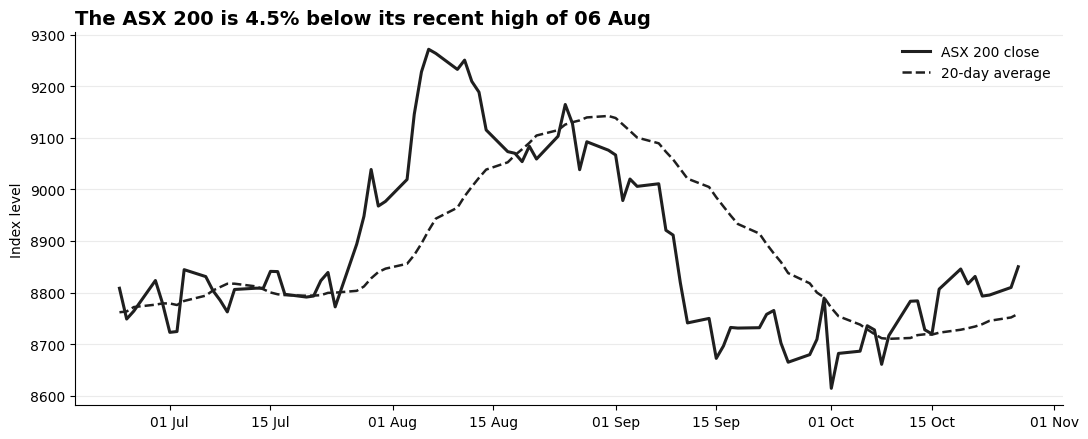

In [8]:
# 8. Price chart: 90 trading days with the 20-day average
if from_peak > -0.5:
    headline = "The ASX 200 is at its 90-day high"
else:
    headline = f"The ASX 200 is {abs(from_peak):.1f}% below its recent high of {peak_date:%d %b}"

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(last90["date"], last90[CLOSE], color="#1f1f1f", lw=2.2, label="ASX 200 close")
ax.plot(last90["date"], last90["rolling_avg_20d"], color="#1f1f1f", lw=1.8, ls="--", label="20-day average")
ax.set_title(headline, loc="left", fontsize=14, fontweight="bold")
ax.set_ylabel("Index level")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
if provisional:
    fig.text(0.01, 0.01, f"Latest day ({latest['date']:%d %b}) left out: figures not final yet.", fontsize=9, color="#595959")
fig.tight_layout()
fig.savefig("price_chart.png", dpi=150, bbox_inches="tight")
plt.show()

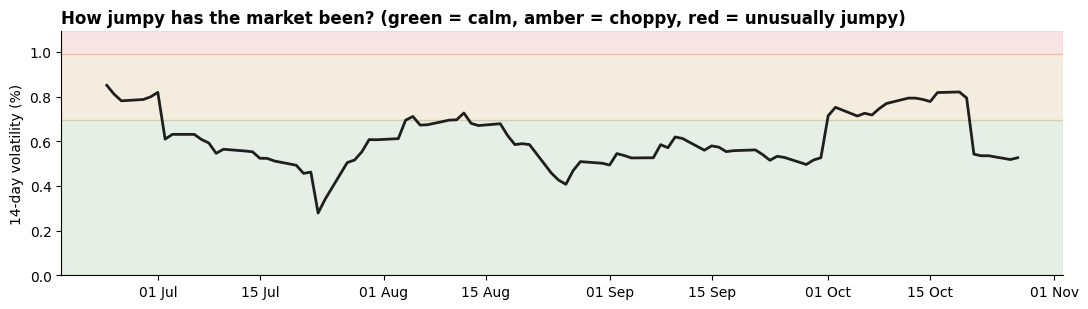

In [9]:
# 9. Volatility chart with the RAG bands (shows WHY the signal has its colour)
top = max(last90["volatility_14d"].max(), p80) * 1.1
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axhspan(0, p50, color="#2e7d32", alpha=0.12)
ax.axhspan(p50, p80, color="#b26a00", alpha=0.12)
ax.axhspan(p80, top, color="#c62828", alpha=0.12)
ax.plot(last90["date"], last90["volatility_14d"], color="#1f1f1f", lw=2)
ax.set_ylim(0, top)
ax.set_title("How jumpy has the market been? (green = calm, amber = choppy, red = unusually jumpy)", loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("14-day volatility (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("volatility_chart.png", dpi=150, bbox_inches="tight")
plt.show()

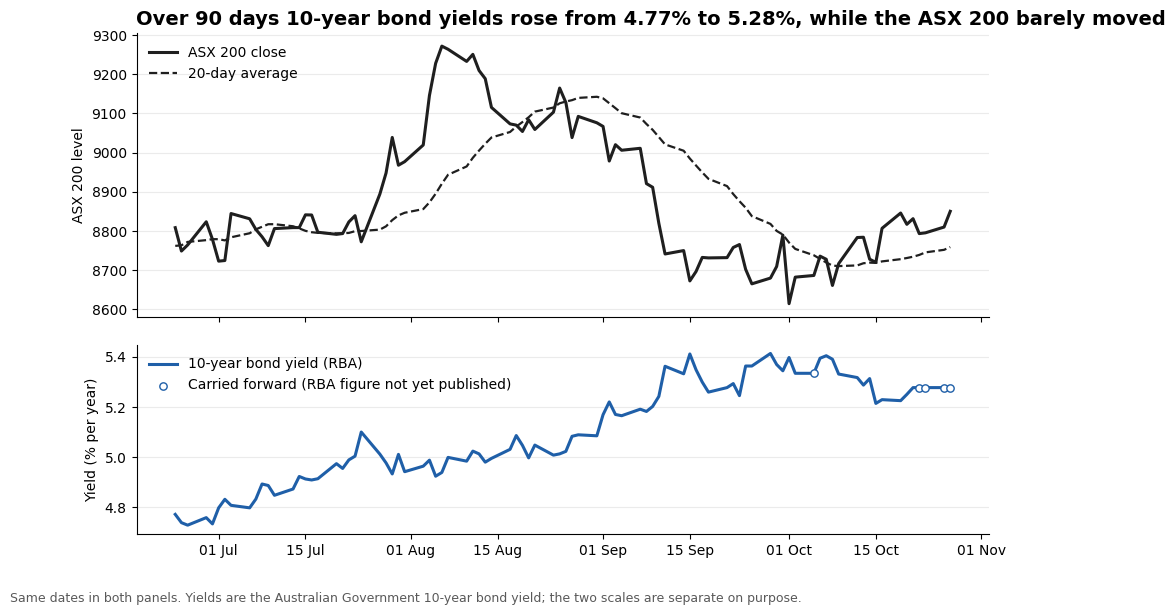

How to read this:
Over the last 30 trading days (using 24 days with real yield data), daily moves in the index and in yields showed a moderate tendency to move in opposite directions: when yields rose, shares often fell.
Correlation: -0.46   (-1 = always opposite, 0 = no link, +1 = always together)


In [10]:
# 10. Macro overlay: index and bond yield on the SAME dates, stacked so each keeps its own scale
if abs(y_change_pp) < 0.05:
    y_phrase = "10-year bond yields were flat"
else:
    y_phrase = f"10-year bond yields {'rose' if y_change_pp > 0 else 'fell'} from {y_start:.2f}% to {y_end:.2f}%"
if abs(asx_change) < 1:
    a_phrase = "the ASX 200 barely moved"
else:
    a_phrase = f"the ASX 200 {'gained' if asx_change > 0 else 'lost'} {abs(asx_change):.1f}%"
overlay_headline = f"Over 90 days {y_phrase}, while {a_phrase}"

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 2], "hspace": 0.12})
ax1.plot(last90["date"], last90[CLOSE], color="#1f1f1f", lw=2.2, label="ASX 200 close")
ax1.plot(last90["date"], last90["rolling_avg_20d"], color="#1f1f1f", lw=1.6, ls="--", label="20-day average")
ax1.set_ylabel("ASX 200 level")
ax1.set_title(overlay_headline, loc="left", fontsize=14, fontweight="bold")
ax1.legend(frameon=False, loc="upper left")

pub90 = last90[~last90[YIELD_FILLED].astype(bool)]
fill90 = last90[last90[YIELD_FILLED].astype(bool)]
ax2.plot(last90["date"], last90[YIELD], color="#1f5fa8", lw=2.2, label="10-year bond yield (RBA)")
if len(fill90):
    ax2.scatter(fill90["date"], fill90[YIELD], facecolors="white", edgecolors="#1f5fa8", s=28, zorder=3,
                label="Carried forward (RBA figure not yet published)")
ax2.set_ylabel("Yield (% per year)")
ax2.legend(frameon=False, loc="upper left")

for a in (ax1, ax2):
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", alpha=0.25)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.text(0.01, 0.005, "Same dates in both panels. Yields are the Australian Government 10-year bond yield; the two scales are separate on purpose.", fontsize=9, color="#595959")
fig.savefig("macro_overlay_chart.png", dpi=150, bbox_inches="tight")
plt.show()

print("How to read this:")
print(f"Over the last 30 trading days (using {r_pairs} days with real yield data), daily moves in the index and in yields {link_words(r_now)}")
print(f"Correlation: {r_now:.2f}   (-1 = always opposite, 0 = no link, +1 = always together)")

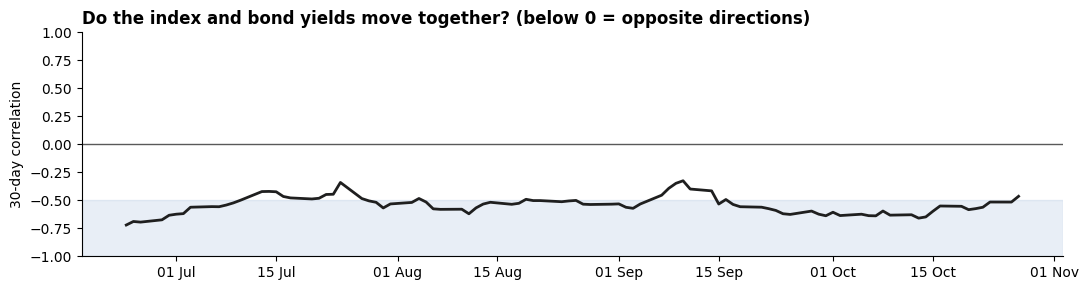

Share of the last 90 days with a negative 30-day correlation: 100%
Whole-period correlation of daily moves: -0.38


In [11]:
# 11. Analyst view (optional, for the report appendix): how steady is the link?
fig, ax = plt.subplots(figsize=(11, 3))
ax.axhline(0, color="#595959", lw=1)
ax.axhspan(-1, -0.5, color="#1f5fa8", alpha=0.10)
ax.plot(last90["date"], last90["corr_30d"], color="#1f1f1f", lw=2)
ax.set_ylim(-1, 1)
ax.set_ylabel("30-day correlation")
ax.set_title("Do the index and bond yields move together? (below 0 = opposite directions)", loc="left", fontsize=12, fontweight="bold")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("correlation_chart.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Share of the last 90 days with a negative 30-day correlation: {(last90['corr_30d'] < 0).mean()*100:.0f}%")
print(f"Whole-period correlation of daily moves: {data['daily_return_pct'].corr(data['yield_change_bp']):.2f}")

In [12]:
# 12. Does the RAG rule behave sensibly? Check the biggest one-day falls of the past year.
# (The overall Green/Amber/Red split is about 50/30/20 by construction, so it proves nothing on its own.)
yr = data.tail(252)
worst = yr.nsmallest(5, "daily_return_pct")[["date", "daily_return_pct", "volatility_14d"]].copy()
worst["status"] = worst["volatility_14d"].apply(rag)
worst

,date,daily_return_pct,volatility_14d,status
214,2026-03-09,-2.847136,1.114267,RED
193,2026-02-06,-2.029433,0.871156,AMBER
359,2026-10-01,-1.989913,0.714702,AMBER
211,2026-03-04,-1.940000,0.880387,AMBER
139,2025-11-18,-1.937159,0.689021,GREEN


In [14]:
# 12b. Sensitivity check: how would different RAG cut-offs have behaved?
# Reuses `year` (the past 252 volatility values) and `worst` (the 5 biggest one-day falls) from the cells above.
vol_year = year
falls = worst

def label(v, amber_start, red_start):
    if v < amber_start:
        return "GREEN"
    return "AMBER" if v <= red_start else "RED"

rows = []
for g, r in [(50, 80), (60, 90), (40, 70)]:
    a, b = np.percentile(vol_year, g), np.percentile(vol_year, r)
    share = vol_year.apply(lambda v: label(v, a, b)).value_counts(normalize=True)
    flagged = sum(label(v, a, b) != "GREEN" for v in falls["volatility_14d"])
    rows.append({
        "cut-offs": f"{g}/{r}",
        "amber starts at": round(a, 2),
        "red starts at": round(b, 2),
        "% green": round(100 * share.get("GREEN", 0)),
        "% amber": round(100 * share.get("AMBER", 0)),
        "% red": round(100 * share.get("RED", 0)),
        "big falls flagged (of 5)": flagged,
    })

print(pd.DataFrame(rows).to_string(index=False))

cut-offs  amber starts at  red starts at  % green  % amber  % red  big falls flagged (of 5)
   50/80             0.69           0.99       50       30     20                         4
   60/90             0.78           1.12       60       30     10                         3
   40/70             0.61           0.89       40       30     30                         5


In [13]:
# 13. Numbers for the report (copy these into your write-up; they change if the data file changes)
summary = {
    "Data range": f"{df['date'].min():%d %b %Y} to {df['date'].max():%d %b %Y} ({len(df)} trading days)",
    "Chart window": f"{last90['date'].min():%d %b} to {last90['date'].max():%d %b %Y}",
    "RAG status": f"{status} (volatility {latest_vol:.2f}, higher than {latest_pct:.0f}% of days this year)",
    "RAG cut-offs": f"50th percentile {p50:.2f}, 80th percentile {p80:.2f} (% per day, past {len(year)} trading days)",
    "ASX 200 over window": f"{asx_change:+.1f}%; {from_peak:.1f}% from its high of {peak_date:%d %b}",
    "10-year yield over window": f"{y_start:.2f}% to {y_end:.2f}% ({y_change_pp:+.2f} percentage points)",
    "30-day correlation": f"{r_now:.2f} using {r_pairs} valid days",
    "Yield carried forward": f"{int(filled.sum())} of {len(df)} rows; last RBA figure {last_published:%d %b %Y}",
}
for k, v in summary.items():
    print(f"{k}: {v}")

Data range: 06 May 2025 to 27 Oct 2026 (378 trading days)
Chart window: 24 Jun to 27 Oct 2026
RAG status: GREEN (volatility 0.53, higher than 24% of days this year)
RAG cut-offs: 50th percentile 0.69, 80th percentile 0.99 (% per day, past 252 trading days)
ASX 200 over window: +0.5%; -4.5% from its high of 06 Aug
10-year yield over window: 4.77% to 5.28% (+0.50 percentage points)
30-day correlation: -0.46 using 24 valid days
Yield carried forward: 6 of 378 rows; last RBA figure 21 Oct 2026


## Limits to state in the write-up
- **The newest yields are carried forward.** The RBA publishes with a delay, so the last few trading days repeat the latest published value (hollow markers on the chart). They are excluded from the correlation.
- **Correlation is not cause.** A negative link says the two tend to move in opposite directions, not that one drives the other. The wording bands (weak / moderate / strong) follow Hearon (2025).
- **Daily versus longer-run.** Daily moves are linked, but over the full 90 days yields rose while the index went nowhere. Mitchell (2021) notes the yield–equity relationship may not hold in the short run and shows more clearly over longer periods.
- **The RAG signal measures recent choppiness, not single drops.** Cell 12 shows that one of the five biggest falls of the year did not turn the signal Amber or Red.
- **Volume is not used.** It has a zero on one day and repeated values, so the dashboard relies on closing prices.